# Многоязычная baseline-модель: английский + русский + казахский

**Проект:** SMS Guard · **Автор:** Омаров М.Е., SIS-2304

Baseline из задания 7 обучена только на английском наборе UCI и на русских и казахских SMS ненадёжна.
Здесь к обучению добавлен синтетический набор `data/raw/synthetic_ru_kk.csv`: **1000 SMS на русском и
1000 на казахском** (по 50% мошеннических), созданный скриптом `ml/data/generate_ru_kk.py` из 170 шаблонов.

Сравниваются две модели с одинаковым Pipeline (признаки задания 6 + Logistic Regression):

| Модель | Обучающие данные |
| :--- | :--- |
| `en` — baseline задания 7 | UCI train (3594 SMS, английский) |
| `multi` — многоязычная | UCI train + синтетический ru/kk train |

**Как обеспечена честность проверки:**
1. Синтетический набор делится **по шаблонам**: в validation попадают шаблоны, которых модель не видела.
2. 150 SMS, написанных вручную (`data/raw/custom_ru_kk.csv`), в обучение **не входят**. Шаблоны генератора написаны
   по тем же схемам, поэтому для каждого ручного SMS измеряется сходство с обучающими данными и отдельно
   приводятся метрики на сообщениях **без близкого аналога** — это самая строгая оценка.
3. Синтетический test и UCI test здесь не используются — они нужны для итоговой модели (задание 8).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 110)

from ml.features import SYNTH_SPLIT_PATH, load_synthetic, make_input  # noqa: E402
from ml.train_baseline import FEATURE_COLUMNS, build_baseline, load_training_data  # noqa: E402

FIG_DIR = PROJECT_ROOT / "docs" / "figures"
synth = load_synthetic()
custom = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "custom_ru_kk.csv")
custom = pd.concat([custom, make_input(custom["text"]).set_axis(custom.index)], axis=1)

## 1. Синтетический набор и его разбиение по шаблонам

In [2]:
all_synth = pd.concat([part.assign(часть=name) for name, part in synth.items()], ignore_index=True)
overview = all_synth.pivot_table(index=["lang", "label_name"], columns="часть", values="id",
                                 aggfunc="count")[["train", "val", "test"]]
overview["всего"] = overview.sum(axis=1)
print("Шаблонов в train / val / test:",
      [all_synth.loc[all_synth["часть"] == p, "template_id"].nunique() for p in ("train", "val", "test")])
print("Общих шаблонов между train и val:",
      len(set(synth["train"]["template_id"]) & set(synth["val"]["template_id"])))
overview

Шаблонов в train / val / test: [110, 30, 30]
Общих шаблонов между train и val: 0


часть            train  val  test  всего
lang label_name                         
kk   fraud         305   97    98    500
     safe          325   85    90    500
ru   fraud         305   97    98    500
     safe          323   88    89    500

In [3]:
pd.crosstab([all_synth["lang"], all_synth["category"]], all_synth["часть"])[["train", "val", "test"]]

часть                train  val  test
lang category                        
kk   bank_legit        111   26    31
     card_block         37   12    13
     code_request       36   12    12
     delivery           36   12    12
     delivery_legit     45   13    13
     fake_bank          52   13    13
     gov                36   12    12
     invest             36   12    12
     personal          106   26    30
     prize              36   12    12
     promo_legit        36   15    12
     relative           36   12    12
     service            27    5     4
ru   bank_legit        110   27    33
     card_block         37   12    13
     code_request       36   12    12
     delivery           36   12    12
     delivery_legit     45   18    13
     fake_bank          52   13    13
     gov                36   12    12
     invest             36   12    12
     personal          108   26    26
     prize              36   12    12
     promo_legit        33   13    13
     relative           36   12    12
     service            27    4     4

In [4]:
print("Примеры синтетических SMS:")
all_synth.groupby(["lang", "label_name"]).head(2)[["lang", "label_name", "category", "text"]]

Примеры синтетических SMS:


,lang,label_name,category,text
0,ru,fraud,fake_bank,"Forte: обнаружен вход с нового устройства. Если это не вы, подтвердите личность: pay-check.test ⚠️"
1,ru,fraud,fake_bank,"Freedom: обнаружен вход с нового устройства. Если это не вы, подтвердите личность: http://bankonline.examp..."
305,ru,safe,personal,Ок. Привет! Встречаемся завтра в 11:00 у ТРЦ.
306,ru,safe,personal,Привет! Встречаемся завтра в 13:00 в кафе.
628,kk,fraud,fake_bank,"НАЗАР АУДАРЫҢЫЗ! Құрметті клиент! Freedom қосымшасындағы деректеріңізді жаңартыңыз, әйтпесе қолжетімділік ..."
629,kk,fraud,fake_bank,"Маңызды! Құрметті клиент! Forte қосымшасындағы деректеріңізді жаңартыңыз, әйтпесе қолжетімділік шектеледі:..."
933,kk,safe,personal,"Жарайды. Мен жолдамын, 50 минуттан кейін жетемін."
934,kk,safe,personal,"Жарайды. Мен жолдамын, 30 минуттан кейін жетемін. 😊"


## 2. Обучение двух моделей

In [5]:
train_en, vals = load_training_data(multi=False)
train_multi, vals_multi = load_training_data(multi=True)
print("Обучающая выборка en:", len(train_en), "| multi:", len(train_multi),
      train_multi["lang"].value_counts().to_dict())

models = {
    "en": build_baseline().fit(train_en[FEATURE_COLUMNS], train_en["label"]),
    "multi": build_baseline().fit(train_multi[FEATURE_COLUMNS], train_multi["label"]),
}

Обучающая выборка en: 3594 | multi: 4852 {'en': 3594, 'kk': 630, 'ru': 628}


## 3. Насколько ручной набор похож на обучающие данные

Для каждого из 150 ручных SMS находим самое похожее сообщение в обучающей выборке модели `multi`
(косинусное сходство символьных TF-IDF-векторов, 0 — ничего общего, 1 — совпадение).
Сообщения со сходством ≥ 0,6 считаем имеющими **близкий аналог** в обучении.

In [6]:
sim_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(train_multi["text_clean"])
similarity = cosine_similarity(sim_vec.transform(custom["text_clean"]),
                               sim_vec.transform(train_multi["text_clean"])).max(axis=1)
custom["max_sim"] = similarity.round(3)
custom["analog"] = np.where(custom["max_sim"] >= 0.6, "есть аналог", "нет аналога")
pd.crosstab([custom["lang"], custom["label_name"]], custom["analog"], margins=True, margins_name="всего")

analog            есть аналог  нет аналога  всего
lang  label_name                                 
kk    fraud                14           11     25
      safe                 11           14     25
ru    fraud                25           25     50
      safe                 26           24     50
всего                      76           74    150

## 4. Метрики по языкам и наборам

Порог 0,5. Precision / Recall / F1 — для класса «мошенничество».

In [7]:
eval_sets = {
    "UCI validation (en)": vals["en"],
    "Синтетика validation (ru)": vals_multi["ru"],
    "Синтетика validation (kk)": vals_multi["kk"],
    "Ручной набор (ru)": custom[custom["lang"] == "ru"],
    "Ручной набор (kk)": custom[custom["lang"] == "kk"],
    "Ручной, без аналога (ru)": custom[(custom["lang"] == "ru") & (custom["analog"] == "нет аналога")],
    "Ручной, без аналога (kk)": custom[(custom["lang"] == "kk") & (custom["analog"] == "нет аналога")],
}


def evaluate(model, data):
    y = data["label"].to_numpy()
    p = model.predict_proba(data[FEATURE_COLUMNS])[:, 1]
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"SMS": len(y), "fraud": int(y.sum()),
            "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan,
            "FP": int(fp), "FN": int(fn)}


rows = [{"Набор": name, "Модель": m, **evaluate(model, data)}
        for name, data in eval_sets.items() for m, model in models.items()]
results = pd.DataFrame(rows).set_index(["Набор", "Модель"])
results.round(3)

SMS  fraud  Precision  ...  ROC-AUC  FP  FN
Набор                     Модель                         ...                 
UCI validation (en)       en      770     93      0.966  ...    0.994   3   9
                          multi   770     93      0.976  ...    0.994   2  10
Синтетика validation (ru) en      185     97      0.764  ...    1.000  30   0
                          multi   185     97      1.000  ...    1.000   0   0
Синтетика validation (kk) en      182     97      0.669  ...    0.999  48   0
                          multi   182     97      0.960  ...    1.000   4   0
Ручной набор (ru)         en      100     50      0.772  ...    0.892  13   6
                          multi   100     50      0.978  ...    0.997   1   5
Ручной набор (kk)         en       50     25      0.778  ...    0.896   6   4
                          multi    50     25      1.000  ...    1.000   0   2
Ручной, без аналога (ru)  en       49     25      0.786  ...    0.902   6   3
                          multi    49     25      0.955  ...    0.990   1   4
Ручной, без аналога (kk)  en       25     11      0.750  ...    0.922   3   2
                          multi    25     11      1.000  ...    1.000   0   1

[14 rows x 8 columns]

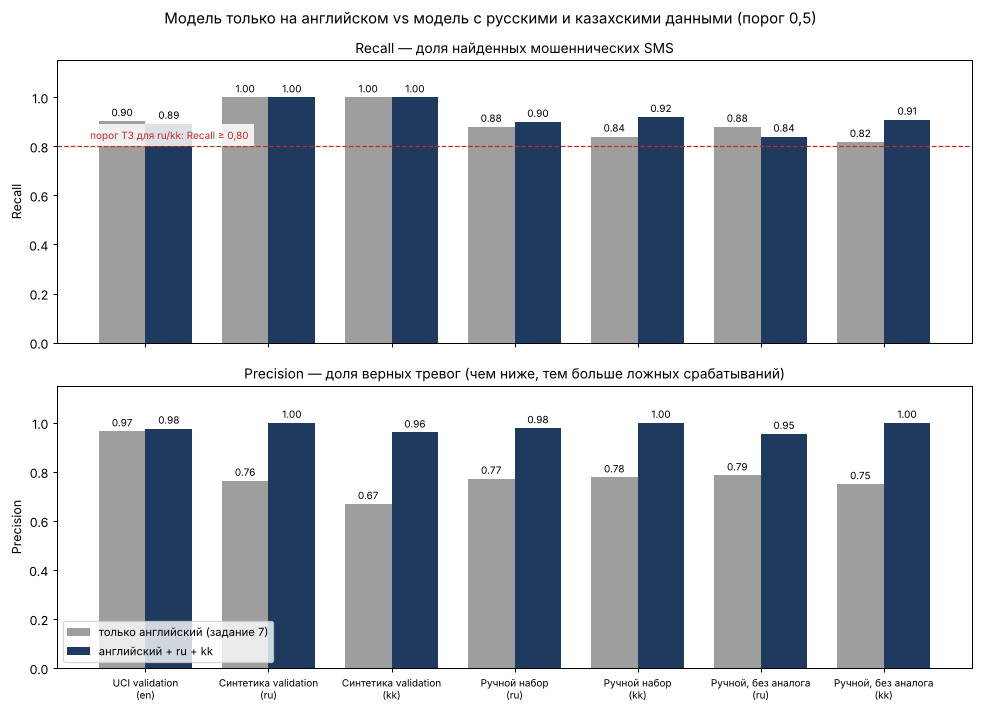

In [8]:
order = list(eval_sets)
labels = [n.replace(" (", "\n(") for n in order]
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
x = np.arange(len(order))
w = 0.38
for ax, metric, title in [
    (axes[0], "Recall", "Recall — доля найденных мошеннических SMS"),
    (axes[1], "Precision", "Precision — доля верных тревог (чем ниже, тем больше ложных срабатываний)"),
]:
    table = results[metric].unstack("Модель").reindex(order)
    for i, (m, color) in enumerate([("en", "#9e9e9e"), ("multi", "#1f3a5f")]):
        b = ax.bar(x + (i - 0.5) * w, table[m], w, color=color,
                   label="только английский (задание 7)" if m == "en" else "английский + ru + kk")
        ax.bar_label(b, labels=[f"{v:.2f}" for v in table[m]], fontsize=8, padding=2)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel(metric)
    ax.set_title(title, fontsize=11)
axes[0].axhline(0.80, color="#c62828", linestyle="--", linewidth=1)
axes[0].text(-0.45, 0.83, "порог ТЗ для ru/kk: Recall ≥ 0,80", color="#c62828", fontsize=8,
             bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85})
axes[1].legend(loc="lower left", fontsize=9)
axes[1].set_xticks(x, labels, fontsize=8)
fig.suptitle("Модель только на английском vs модель с русскими и казахскими данными (порог 0,5)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "07b_multilang_recall_precision.png", dpi=150)

## 5. Ошибки многоязычной модели на ручном наборе

In [9]:
custom["p_en"] = models["en"].predict_proba(custom[FEATURE_COLUMNS])[:, 1].round(3)
custom["p_multi"] = models["multi"].predict_proba(custom[FEATURE_COLUMNS])[:, 1].round(3)
errors = custom[(custom["p_multi"] >= 0.5).astype(int) != custom["label"]]
print(f"Ошибок модели multi на ручном наборе: {len(errors)} из {len(custom)}")
errors[["lang", "label_name", "category", "p_multi", "max_sim", "text"]]

Ошибок модели multi на ручном наборе: 8 из 150


,lang,label_name,category,p_multi,max_sim,text
12,ru,fraud,card_block,0.248,0.452,"Банк: подозрительная активность. Карта заблокирована. Ответьте на это сообщение, указав номер карты и срок..."
30,ru,fraud,relative,0.448,0.329,"Брат, выручай, срочно скинь 20 000 на этот номер, потом объясню. Свой телефон потерял."
33,ru,fraud,code_request,0.253,0.264,"Оператор связи: для продления номера продиктуйте код, который придёт вам в SMS."
34,ru,fraud,code_request,0.437,0.910,"Мы ошибочно отправили вам код. Пожалуйста, перешлите его на этот номер, это срочно."
36,ru,fraud,code_request,0.234,0.322,"Для получения выплаты сообщите код из SMS, который придёт в течение минуты."
97,ru,safe,promo_legit,0.558,0.331,Новое меню уже в ресторане! Подробнее на https://www.example.com/menu
114,kk,fraud,relative,0.335,0.643,"Аға, көмектес, шұғыл осы нөмірге 20 000 жібер, кейін түсіндіремін. Анама айтпа."
117,kk,fraud,code_request,0.472,0.351,"Қате жіберілген кодты осы нөмірге қайта жіберіңізші, бұл өте шұғыл."


In [10]:
print("Самые неуверенные верные ответы (вероятность ближе всего к порогу):")
ok = custom[(custom["p_multi"] >= 0.5).astype(int) == custom["label"]]
ok.assign(dist=(ok["p_multi"] - 0.5).abs()).nsmallest(6, "dist")[["lang", "label_name", "p_multi", "text"]]

Самые неуверенные верные ответы (вероятность ближе всего к порогу):


,lang,label_name,p_multi,text
28,ru,fraud,0.526,"Тётя, это я. Меня задержали, нужно срочно заплатить штраф 80 000. Переведи на этот номер, пожалуйста, это ..."
25,ru,fraud,0.529,"Мама, это я, пишу с чужого номера. У меня проблемы, срочно переведи 50 000 на этот номер, потом всё объясн..."
118,kk,fraud,0.531,Төлемді алу үшін SMS арқылы келетін кодты айтыңыз.
40,ru,fraud,0.590,Уведомление о штрафе ПДД. Фото нарушения и оплата: http://traffic-fine.example/photo
29,ru,fraud,0.668,"Мам, срочно! Попал в аварию, нужны деньги на лечение. Передай 200 000 человеку, который приедет. Не звони ..."
147,kk,safe,0.295,Қазан айындағы коммуналдық қызметтер шоты дайын. Сомасы 18 400 тг.


## 6. Проверка на новых сообщениях

In [11]:
from ml.predictor import predict_sms  # noqa: E402

examples = [
    "Привет! Встречаемся завтра в 18:00 у входа.",
    "Ваша карта заблокирована! Срочно подтвердите данные по ссылке: http://secure-bank-verify.example/login",
    "Мама, у меня проблемы, срочно скинь 40 000 на этот номер, потом объясню",
    "Халык: зачисление 230 000 тг, заработная плата. Карта *5521",
    "Сәлем! Ертең сағат 10:00-де кездесеміз бе?",
    "Картаңыз бұғатталды. Жедел түрде мына сілтеме арқылы растаңыз: http://bank-kz-verify.test",
    "Растау коды 77310. Кодты ешкімге айтпаңыз.",
    "URGENT! You have won a £1000 prize. Call 09061701461 now!",
]
pd.DataFrame([{"Текст": t,
               "en": predict_sms(t, model=models["en"], threshold=0.5)["probability"],
               "multi": predict_sms(t, model=models["multi"], threshold=0.5)["probability"]}
              for t in examples])

,Текст,en,multi
0,Привет! Встречаемся завтра в 18:00 у входа.,0.4548,0.0220
1,Ваша карта заблокирована! Срочно подтвердите данные по ссылке: http://secure-bank-verify.example/login,0.9845,0.9945
2,"Мама, у меня проблемы, срочно скинь 40 000 на этот номер, потом объясню",0.5792,0.3542
3,"Халык: зачисление 230 000 тг, заработная плата. Карта *5521",0.9467,0.1362
4,Сәлем! Ертең сағат 10:00-де кездесеміз бе?,0.2708,0.0235
5,Картаңыз бұғатталды. Жедел түрде мына сілтеме арқылы растаңыз: http://bank-kz-verify.test,0.9560,0.9907
6,Растау коды 77310. Кодты ешкімге айтпаңыз.,0.4217,0.0979
7,URGENT! You have won a £1000 prize. Call 09061701461 now!,0.9998,0.9997


## 7. Выводы

1. **Модель только на английском переносится на ru/kk плохо.** Мошенничество она часто находит благодаря ссылкам, суммам и ручным признакам (Recall 0,88 на русском и 0,84 на казахском ручном наборе), но даёт много ложных тревог: Precision 0,77–0,78, на синтетической validation — 30 (ru) и 48 (kk) ложных срабатываний. ROC-AUC на ручном наборе — 0,89–0,90.
2. **Добавление 2000 русских и казахских SMS почти убирает ложные тревоги.** На ручном наборе: русский — Precision 0,978, Recall 0,90, F1 0,938; казахский — Precision 1,00, Recall 0,92, F1 0,958; ROC-AUC 0,997 и 1,00.
3. **Строгая оценка — ручные SMS без близкого аналога в обучении** (74 из 150): русский — Recall 0,84, Precision 0,955; казахский — Recall 0,91, Precision 1,00. Требование ТЗ для заявления поддержки языка (Recall ≥ 0,80) выполнено на validation и ручном наборе; окончательно оно проверяется на test в задании 8.
4. **Качество на английском не ухудшилось:** F1 0,933 у обеих моделей (Recall 0,903 → 0,892, одна дополнительная пропущенная SMS; Precision 0,966 → 0,976).
5. **Оставшиеся ошибки** — 7 пропущенных мошеннических SMS без ссылки («родственник в беде», «запрос кода», ответ с данными карты) и одна реклама со ссылкой. Все 7 пропусков ловит словарь правил, 4 из них — группой `CODE_REQUEST`, которая в модуле риска (задание 13) поднимает Risk Score минимум до 70. Порог классификации подбирается в задании 8.
6. **Ограничения.** Синтетические данные проще реальных: на синтетической validation метрики близки к 1,0, и эти числа нельзя переносить на настоящие SMS. Все ru/kk-сообщения написаны одним автором по одним и тем же схемам. Ручной набор маленький: в казахском без аналога 11 мошеннических SMS, одна ошибка меняет Recall на 9 п. п. Поэтому поддержка русского и казахского заявляется только в пределах этих проверок, с предупреждением в интерфейсе.